| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../14_PROBLEMAS_INVERSOS/14_1_Problema_inverso.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_2_PINNs.ipynb) |

# 15.1 Physics-Informed Neural Networks: aprender una función que respeta una ecuación

En SciML combinamos **datos, modelos matemáticos y aprendizaje**. Una PINN representa una solución mediante una red neuronal y utiliza una ecuación diferencial como parte del criterio de entrenamiento. En este notebook construirás una PINN pequeña desde cero, sin paquetes especializados.

**Objetivos:** distinguir ajuste de datos y residuo físico; calcular derivadas con autograd; resolver una ODE; comparar contra una solución exacta y un solver; medir el error en puntos nuevos.

**Prerrequisitos:** derivadas, ODE, redes neuronales y descenso de gradiente. Consulta los capítulos 5, 10 y 12 si una expresión resulta nueva. **Librerías:** NumPy, Matplotlib, SciPy y PyTorch. Todos los experimentos utilizan CPU y datos generados aquí. Ejecuta las celdas de arriba hacia abajo.

## 1. Un problema físico antes de elegir la red

Imagina una sustancia cuya concentración disminuye proporcionalmente a la concentración presente. Si $u(t)$ es la concentración normalizada, entonces

$$\frac{du}{dt}=-ku,\qquad u(0)=1,\qquad k>0.$$

El parámetro $k$ tiene unidades de tiempo inverso; $kt$ debe ser adimensional. Separando variables, $du/u=-k\,dt$, integramos para obtener $\log u=-kt+C$. La condición inicial determina $C=0$, por lo que

$$\boxed{u(t)=e^{-kt}.}$$

La ecuación describe un mecanismo; las observaciones indican qué ocurrió en un experimento. En problemas más complejos conocemos el mecanismo pero no una solución explícita. Aquí sí la conocemos: eso permite comprobar cada parte del aprendizaje antes de pasar a una PDE.

Usaremos $k=1$ y $t\in[0,3]$. No necesitamos entrenar una red para este problema sencillo; lo elegimos porque podemos entender y verificar el procedimiento completo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import torch
from torch import nn

torch.manual_seed(15)
torch.set_num_threads(1)
torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(15)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})
k = 1.0
T = 3.0
exacta = lambda t: np.exp(-k * t)
print('PyTorch:', torch.__version__, '| dispositivo: CPU')

PyTorch: 2.14.1+cpu | dispositivo: CPU


## 2. ¿Qué aprende una red supervisada?

Una red $u_\theta(t)$ recibe un número y produce otro. Sus pesos y sesgos forman $\theta$. Con pares $(t_i,y_i)$ podemos minimizar

$$\mathcal L_d(\theta)=\frac1{N_d}\sum_i[u_\theta(t_i)-y_i]^2.$$

Esta pérdida informa a la red sobre los puntos observados. No exige que su pendiente tenga el significado físico correcto entre esos puntos. Tampoco garantiza concentraciones positivas o una extrapolación razonable.

Generaremos seis mediciones **sin ruido**, solo hasta $t=1$. Reservaremos $1<t\leq3$ para estudiar extrapolación. Así podemos separar falta de datos de ruido de medición. La curva exacta se dibuja como referencia y nunca se utiliza como etiqueta en los puntos no observados.

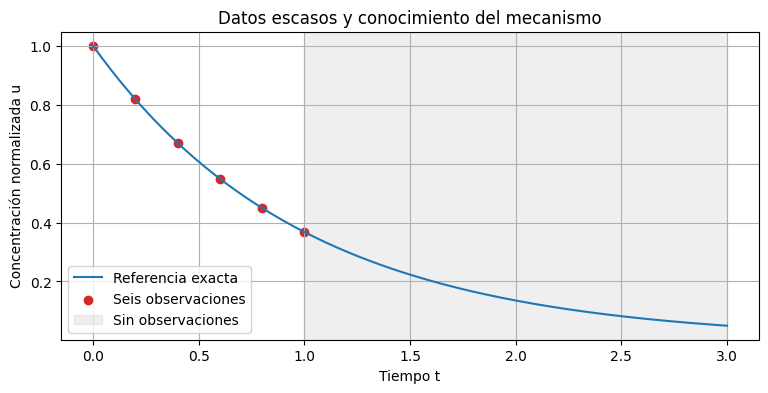

In [2]:
t_datos = np.linspace(0, 1, 6)
y_datos = exacta(t_datos)
t_vista = np.linspace(0, T, 301)
plt.plot(t_vista, exacta(t_vista), label='Referencia exacta')
plt.scatter(t_datos, y_datos, color='tab:red', label='Seis observaciones')
plt.axvspan(1, T, alpha=0.12, color='gray', label='Sin observaciones')
plt.xlabel('Tiempo t'); plt.ylabel('Concentración normalizada u')
plt.title('Datos escasos y conocimiento del mecanismo'); plt.legend(); plt.show()
td = torch.tensor(t_datos[:, None])
yd = torch.tensor(y_datos[:, None])

## 3. Convertir una ecuación en un residuo

Reordenamos la ODE:

$$u'(t)+ku(t)=0.$$

Al sustituir la función aprendida obtenemos el residuo

$$\boxed{r_\theta(t)=\partial_tu_\theta(t)+ku_\theta(t).}$$

Una solución exacta produce residuo cero en todo el intervalo. Elegimos puntos de **colocación** $t_j^{(r)}$ donde evaluarlo:

$$\mathcal L_r=\frac1{N_r}\sum_j r_\theta(t_j^{(r)})^2.$$

Estos puntos no son mediciones: no contienen etiquetas $u(t_j)$. Solo indican dónde pedir a la red que satisfaga la ecuación. Una PINN puede utilizar datos, condiciones y residuos a la vez; disponer de datos interiores no es una obligación para resolver un problema directo bien planteado.

Un residuo pequeño en 64 puntos no certifica la ecuación en todo el continuo. Más adelante usaremos una malla de comprobación diferente.

## 4. La condición inicial elimina la ambigüedad

La ecuación $u'+ku=0$ admite todas las funciones $Ce^{-kt}$. También admite $u=0$. Si solo minimizamos $\mathcal L_r$, una concentración nula puede parecer una respuesta perfecta. Necesitamos imponer $u(0)=1$:

$$\mathcal L_0=[u_\theta(0)-1]^2.$$

La pérdida total será

$$\boxed{\mathcal L=\lambda_d\mathcal L_d+\lambda_r\mathcal L_r+\lambda_0\mathcal L_0.}$$

Usaremos pesos iguales porque las variables ya están normalizadas. En un sistema con presión en pascales y velocidad en metros por segundo, sumar pérdidas sin escalarlas puede hacer que domine la variable de mayor magnitud. Adimensionalizar tiene significado físico y ayuda a la optimización.

También podríamos construir $u_\theta(t)=1+tN_\theta(t)$ para cumplir la condición inicial de forma exacta. Aquí usaremos una penalización para observar su error por separado; el próximo notebook trabajará con condiciones impuestas mediante la arquitectura.

## 5. Diferenciación automática: dos derivadas diferentes

Necesitamos la derivada respecto a la **entrada** $t$ para formar $r_\theta$. Después necesitamos derivadas de $\mathcal L$ respecto a los **parámetros** para entrenar.

Autograd aplica la regla de la cadena a las operaciones del programa. No aproxima $u'$ con un cociente incremental. Sin embargo, las operaciones se ejecutan con precisión finita, y diferenciamos la función implementada, no una solución física desconocida.

En PyTorch, `requires_grad=True` registra la dependencia respecto a un tensor. `create_graph=True` permite que la derivada de entrada participe en un nuevo grafo diferenciable. Es necesario para retropropagar a través del residuo y para calcular derivadas de segundo orden. `grad_outputs=ones_like(u)` representa una suma de salidas; entrega las derivadas punto a punto cuando la red procesa muestras independientemente. Capas que mezclan las muestras necesitan un tratamiento diferente.

Residuo máximo de la solución exacta: 0.0


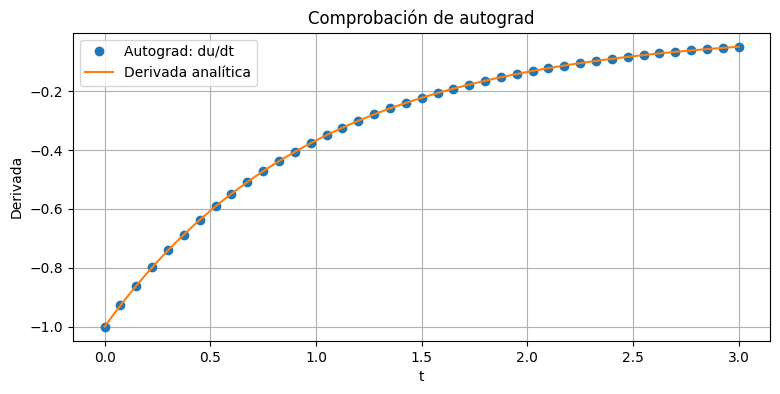

In [3]:
t_demo = torch.linspace(0, T, 41).reshape(-1, 1).requires_grad_(True)
u_demo = torch.exp(-k * t_demo)
du_demo = torch.autograd.grad(u_demo, t_demo, torch.ones_like(u_demo),
                              create_graph=True)[0]
res_demo = du_demo + k * u_demo
print('Residuo máximo de la solución exacta:', res_demo.abs().max().item())
plt.plot(t_demo.detach().numpy(), du_demo.detach().numpy(), 'o',
         label='Autograd: du/dt')
plt.plot(t_vista, -k * exacta(t_vista), label='Derivada analítica')
plt.xlabel('t'); plt.ylabel('Derivada'); plt.title('Comprobación de autograd')
plt.legend(); plt.show()

## 6. Arquitectura y puntos de colocación

Usamos una MLP con dos capas ocultas de 24 neuronas y activación `tanh`. Una PINN debe tener las derivadas exigidas por la ecuación. `tanh` es suave; ReLU tiene segunda derivada cero casi en todas partes y resulta problemática para una PDE que requiere $u_{xx}$.

La entrada se transforma a $[-1,1]$ mediante $s=2t/T-1$. Como el cambio de escala ocurre dentro de `forward`, autograd incorpora automáticamente $ds/dt=2/T$. Cambiar coordenadas fuera del grafo y olvidar esa regla alteraría la ecuación entrenada.

Las dos redes partirán de los mismos pesos. Una utilizará observaciones y condición inicial; la otra añadirá el residuo. Esto hace más clara la comparación, aunque una sola semilla no es suficiente para una conclusión estadística general.

In [4]:
class RedConcentracion(nn.Module):
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(1, 24), nn.Tanh(),
                                 nn.Linear(24, 24), nn.Tanh(), nn.Linear(24, 1))
    def forward(self, t):
        return self.red(2 * t / T - 1)

supervisada = RedConcentracion()
pinn = RedConcentracion()
pinn.load_state_dict(supervisada.state_dict())
tr = torch.linspace(0, T, 64).reshape(-1, 1).requires_grad_(True)
t0 = torch.zeros((1, 1))

def residuo(modelo, t):
    u = modelo(t)
    du = torch.autograd.grad(u, t, torch.ones_like(u), create_graph=True)[0]
    return du + k * u

print('Parámetros por red:', sum(p.numel() for p in pinn.parameters()))
print('Observaciones:', len(td), '| puntos de colocación:', len(tr))

Parámetros por red: 673
Observaciones: 6 | puntos de colocación: 64


## 7. Entrenar y registrar cada término

Adam actualiza los pesos usando gradientes y estimaciones de sus momentos. La tasa de aprendizaje no tiene unidades de tiempo físico: controla cambios en el espacio de parámetros.

En cada iteración limpiamos gradientes, evaluamos pérdidas, retropropagamos y actualizamos. Para la red supervisada, $\lambda_r=0$; para la PINN, $\lambda_r=1$. La ecuación aporta información en todo $[0,3]$, por lo que ambas usan fuentes de información distintas. La comparación ilustra el valor de conocer la ecuación, no una igualdad de presupuestos informativos.

Guardamos los términos por separado. Una pérdida total decreciente puede esconder una condición inicial incorrecta si otro término disminuye mucho más. Los valores impresos corresponden a esta configuración pequeña, no a una garantía de convergencia para cualquier PINN.

Última pérdida [total, datos, física, inicial]: [3.55801644e-05 1.13008026e-06 3.44425070e-05 7.57721439e-09]


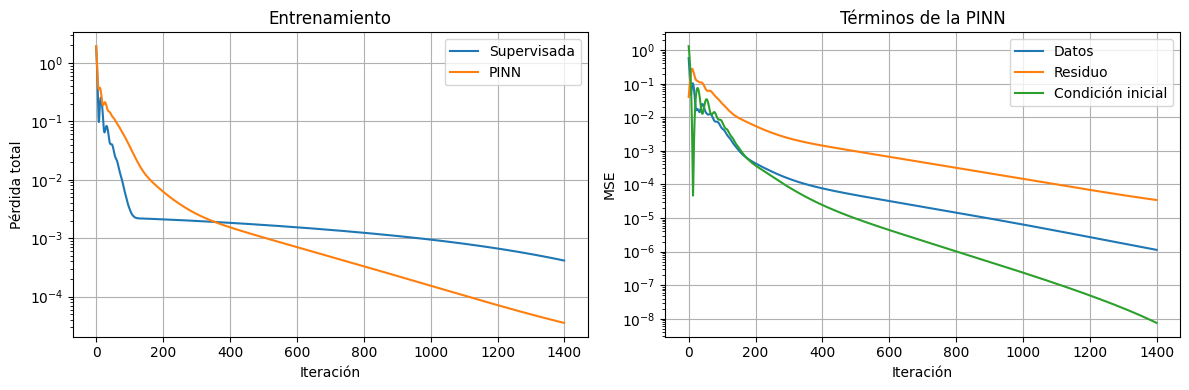

In [5]:
def entrenar(modelo, peso_fisica, pasos=1400):
    opt = torch.optim.Adam(modelo.parameters(), lr=0.003)
    historial = []
    for _ in range(pasos):
        opt.zero_grad(set_to_none=True)
        tr.grad = None
        ld = ((modelo(td) - yd)**2).mean()
        l0 = ((modelo(t0) - 1)**2).mean()
        lr = (residuo(modelo, tr)**2).mean() if peso_fisica else ld.new_zeros(())
        loss = ld + l0 + peso_fisica * lr
        loss.backward()
        opt.step()
        historial.append([loss.item(), ld.item(), lr.item(), l0.item()])
    return np.array(historial)

h_super = entrenar(supervisada, 0.0)
h_pinn = entrenar(pinn, 1.0)
print('Última pérdida [total, datos, física, inicial]:', h_pinn[-1])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(h_super[:, 0], label='Supervisada')
ax[0].semilogy(h_pinn[:, 0], label='PINN')
ax[0].set(xlabel='Iteración', ylabel='Pérdida total', title='Entrenamiento')
for j, nombre in [(1, 'Datos'), (2, 'Residuo'), (3, 'Condición inicial')]:
    ax[1].semilogy(np.maximum(h_pinn[:, j], 1e-16), label=nombre)
ax[1].set(xlabel='Iteración', ylabel='MSE', title='Términos de la PINN')
for a in ax: a.legend()
plt.tight_layout(); plt.show()

## 8. Leer las curvas de entrenamiento

La disminución inicial suele ser rápida porque la red aprende la amplitud y la forma dominante. Más tarde las mejoras son menores: el optimizador debe ajustar pendientes y valores simultáneamente. Oscilaciones pequeñas son posibles incluso sin mini batches.

No compares las pérdidas totales como si fueran el mismo indicador: la PINN suma un término adicional. Para comparar calidad usaremos el mismo error de solución contra la referencia exacta. La comprobación siguiente utiliza 301 puntos, una cantidad y una distribución distintas de la colocación de entrenamiento.

Supervisada | RMSE en intervalo con observaciones: 0.018861458077694633 | RMSE sin datos: 0.25691261654939124
PINN | RMSE en intervalo con observaciones: 0.001175773895188086 | RMSE sin datos: 0.0007669814045647416


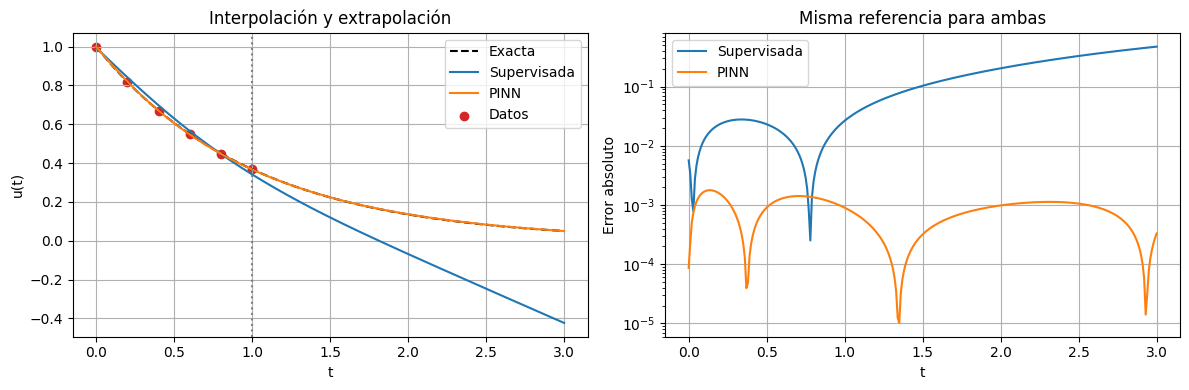

In [6]:
te = torch.tensor(t_vista[:, None])
with torch.no_grad():
    pred_super = supervisada(te).numpy().ravel()
    pred_pinn = pinn(te).numpy().ravel()
ref = exacta(t_vista)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t_vista, ref, 'k--', label='Exacta')
ax[0].plot(t_vista, pred_super, label='Supervisada')
ax[0].plot(t_vista, pred_pinn, label='PINN')
ax[0].scatter(t_datos, y_datos, color='tab:red', label='Datos')
ax[0].axvline(1, color='gray', linestyle=':')
ax[0].set(xlabel='t', ylabel='u(t)', title='Interpolación y extrapolación')
ax[1].semilogy(t_vista, np.abs(pred_super-ref)+1e-12, label='Supervisada')
ax[1].semilogy(t_vista, np.abs(pred_pinn-ref)+1e-12, label='PINN')
ax[1].set(xlabel='t', ylabel='Error absoluto', title='Misma referencia para ambas')
for a in ax: a.legend()
plt.tight_layout(); plt.show()
for nombre, pred in [('Supervisada', pred_super), ('PINN', pred_pinn)]:
    dentro = t_vista <= 1
    print(nombre, '| RMSE en intervalo con observaciones:', np.sqrt(np.mean((pred[dentro]-ref[dentro])**2)),
          '| RMSE sin datos:', np.sqrt(np.mean((pred[~dentro]-ref[~dentro])**2)))

## 9. Comprobar la física en puntos nuevos

Calculamos el residuo en puntos que no se usaron para entrenar. Es posible ajustar valores correctamente y tener pendientes incorrectas; por eso esta comprobación complementa el error de solución.

Para esta ODE incluso podemos relacionar ambos errores. Si $e=u_\theta-u$, entonces $e'+ke=r_\theta$. La fórmula de variación de constantes da

$$e(t)=e(0)e^{-kt}+\int_0^t e^{-k(t-s)}r_\theta(s)\,ds.$$

Si $|r_\theta(s)|\leq R$ **en todo el intervalo**, entonces

$$|e(t)|\leq |e(0)|e^{-kt}+\frac{R}{k}(1-e^{-kt}).$$

Esta cota explica por qué importan condición inicial y residuo. Un máximo calculado en una malla es solo una estimación de $R$; no demuestra una cota continua. Para PDE, estabilidad y regularidad pueden hacer mucho más difícil esta relación.

Supervisada | error inicial: 0.005672938288186713 | RMS residuo nuevo: 0.39649528342579415 | máximo: 0.7701795777828433
PINN | error inicial: 8.656758421732302e-05 | RMS residuo nuevo: 0.004902449690230627 | máximo: 0.030545083990225597


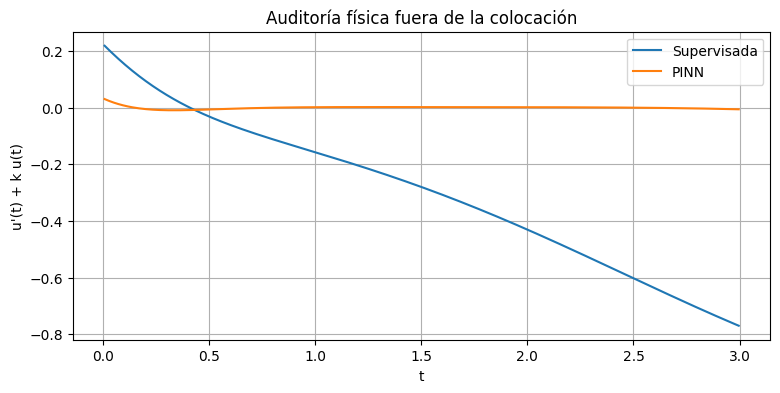

In [7]:
t_audit = torch.linspace(0.007, T-0.004, 277).reshape(-1, 1).requires_grad_(True)
fig, ax = plt.subplots(figsize=(9, 4))
for nombre, modelo in [('Supervisada', supervisada), ('PINN', pinn)]:
    r = residuo(modelo, t_audit).detach().numpy().ravel()
    ax.plot(t_audit.detach().numpy().ravel(), r, label=nombre)
    with torch.no_grad():
        e0 = abs(modelo(t0).item()-1)
    print(nombre, '| error inicial:', e0,
          '| RMS residuo nuevo:', np.sqrt(np.mean(r*r)), '| máximo:', np.max(np.abs(r)))
ax.set(xlabel='t', ylabel="u'(t) + k u(t)", title='Auditoría física fuera de la colocación')
ax.legend(); plt.show()

## 10. Comparar con un método numérico clásico

`solve_ivp` integra un problema de valor inicial usando evaluaciones de su campo vectorial. Una PINN optimiza una función global. En esta ODE pequeña, el solver clásico es una referencia natural y evita el coste de entrenar cientos de pesos.

La utilidad de una PINN puede aparecer al combinar datos incompletos, parámetros desconocidos, geometrías o restricciones específicas. Eso no elimina la necesidad de compararla con métodos clásicos. Reportamos error y número de evaluaciones del solver; no afirmamos una ventaja de tiempo a partir de una sola ejecución.

In [8]:
sol = solve_ivp(lambda t, u: -k*u, (0, T), [1.0],
                t_eval=t_vista, rtol=1e-9, atol=1e-11)
assert sol.success, sol.message
err_solver = np.max(np.abs(sol.y[0]-ref))
err_pinn = np.max(np.abs(pred_pinn-ref))
print('Error máximo solve_ivp:', err_solver, '| evaluaciones:', sol.nfev)
print('Error máximo PINN:', err_pinn)
assert np.isfinite(pred_pinn).all()
assert err_pinn < 0.06, 'La PINN no alcanzó la precisión didáctica esperada.'

Error máximo solve_ivp: 2.4227431172363367e-10 | evaluaciones: 314
Error máximo PINN: 0.0017780016093271733


## 11. Problema directo, problema inverso y modelo híbrido

En el **problema directo** conocemos $k$ y buscamos $u$. En el **inverso** conocemos observaciones de $u$ y buscamos $k$; podríamos entrenar $u_\theta$ y un parámetro $k_\eta$ conjuntamente. Una parametrización $k_\eta=\operatorname{softplus}(\eta)$ asegura positividad.

No todo dato identifica un parámetro. Una observación únicamente en $t=0$ no contiene información sobre $k$: todas las tasas producen $u(0)=1$. Necesitamos mediciones en tiempos con sensibilidad al parámetro y un modelo de ruido.

En un **modelo híbrido**, una parte del mecanismo permanece explícita y otra se aprende, por ejemplo $u'=-ku+g_\theta(u,t)$. Dar demasiada flexibilidad a $g_\theta$ puede ocultar un $k$ incorrecto. La estructura del modelo define qué podemos inferir.

## 12. Errores frecuentes y cómo reconocerlos

| Situación | Consecuencia | Comprobación útil |
|---|---|---|
| Falta de condición inicial | Familia de soluciones o solución nula | Evaluar $u_\theta(0)$ |
| `create_graph=False` al formar el residuo | Se pierde parte del gradiente de entrenamiento | Inspeccionar derivadas y comparar con referencia |
| Extrapolar fuera del intervalo de colocación | No se entrenó la física en esa región | Dibujar dominio de datos y de colocación |
| Pérdidas con escalas incompatibles | Un término domina la optimización | Adimensionalizar y registrar términos |
| Mostrar solo la curva aprendida | Errores visualmente ocultos | Añadir errores y residuos en puntos nuevos |

Una red suave no garantiza conservación, positividad ni estabilidad. En este ejemplo comprobamos el comportamiento de una aproximación; otras aplicaciones pueden necesitar arquitecturas o restricciones adicionales.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../14_PROBLEMAS_INVERSOS/14_1_Problema_inverso.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_2_PINNs.ipynb) |